# AA 279B HW 4

## Imports

In [56]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## MATLAB

In [57]:
import matlab.engine
from matlab.engine import MatlabEngine

In [58]:
# 1. Start the MATLAB process in the background
print("Starting MATLAB engine...")
eng: MatlabEngine = matlab.engine.start_matlab()

Starting MATLAB engine...


In [59]:
stop = False
if stop:
    eng.quit()

## Setup

In [60]:
import os
import sys

sys.path.insert(0, os.path.abspath('..'))

In [126]:
import numpy as np
from numpy.linalg import norm
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
from lamberthub import vallado2013
import plotly.graph_objects as go
from tqdm import tqdm

from constants import DEG_TO_RAD, AU_TO_KM, MU_SUN, DAY_TO_SEC, R_SUN, HOUR_TO_SEC, MU_EARTH, MU_JUPITER, MU_VENUS, R_VENUS_VOLUMETRIC, R_EARTH_VOLUMETRIC, R_JUPITER_VOLUMETRIC, YEAR_TO_DAY
from orbital import rv_from_coe
from plotting import plot_3d
from spacetime import greg_to_jd

## Problem 1

### Part a

In [62]:
from orbital import rv_HCI, OrbitalFlyby

rv_HCI(1, 2461333.837872444, eng)

(array([ 50251258.5359, -31051899.1785,  -7146562.8599]),
 array([16.0423, 43.6725,  2.0978]))

### Part b

In [63]:
gaspra_r_HCI = np.array([7.635070746360724e7, -3.201967071615438e8, 1.17515936590249e7])  # km
gaspra_v_HCI = np.sqrt(MU_SUN/norm(gaspra_r_HCI)) * np.cross([0,0,1], gaspra_r_HCI) / norm(gaspra_r_HCI) # km/s

flybys = [
    OrbitalFlyby("Earth Departure", (1989, 10, 26, 0, 55, 0), 3, mu=MU_EARTH, r_cb=R_EARTH_VOLUMETRIC),
    OrbitalFlyby("Venus Swingby", (1990, 2, 10, 5, 59, 0), 2, mu=MU_VENUS, r_cb=R_VENUS_VOLUMETRIC),
    OrbitalFlyby("Earth Swingby #1", (1990, 12, 8, 20, 35, 0), 3, mu=MU_EARTH, r_cb=R_EARTH_VOLUMETRIC),
    OrbitalFlyby("Gaspra Encounter", (1991, 10, 29, 22, 49, 0), planet_num=None),
    OrbitalFlyby("Earth Swingby #2", (1992, 12, 8, 15, 9, 0), 3, mu=MU_EARTH, r_cb=R_EARTH_VOLUMETRIC),
    OrbitalFlyby("Jupiter Arrival", (1995, 12, 7, 21, 53, 44), 5, mu=MU_JUPITER, r_cb=R_JUPITER_VOLUMETRIC)
]
N_FLYBYS = len(flybys)

for flyby in flybys:
    if flyby.planet_num is None:
        flyby.add_rv_HCI(gaspra_r_HCI, gaspra_v_HCI)
    else:
        flyby.add_rv_HCI(*rv_HCI(flyby.planet_num, flyby.jd, eng))

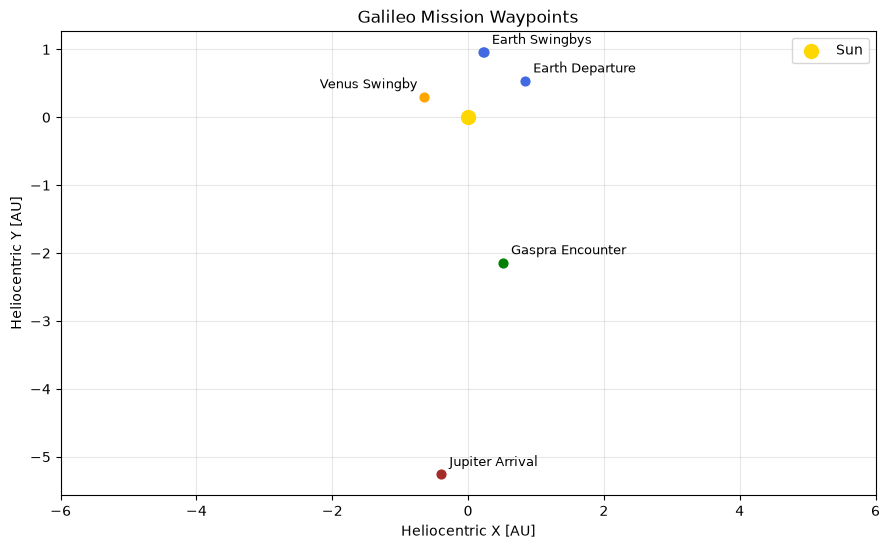

In [64]:
from plotting import plot_flybys

plot_flybys(flybys, xlim=(-6,6))
plt.show()

## Problem 2

### Part a

In [65]:
# Inplace
def calc_transfer(flyby1: OrbitalFlyby, flyby2: OrbitalFlyby):
    """heliocentric asymptotic arrival and departure velocity vectors, using Lambert
    
    `AA279lambert_curtis.m` signature:
    function [v1_out, v2_out, error_out] = AA279lambert_curtis(mu, r1_in, r2_in, dm, nrev, dtsec)
    """
    r1_HCI, r2_HCI = flyby1.r_HCI, flyby2.r_HCI
    t_transfer = (flyby2.jd - flyby1.jd) * DAY_TO_SEC
    result = eng.AA279lambert_curtis(MU_SUN, r1_HCI, r2_HCI, "pro", "ignored", t_transfer, nargout=2)
    
    # heliocentric asymptotic arrival and departure velocity vectors
    v1_HCI, v2_HCI = np.array(result[0]).reshape((3,)), np.array(result[1]).reshape((3,))
    flyby1.v_departure_HCI = v1_HCI
    flyby2.v_arrival_HCI = v2_HCI
    
    # planetocentric asymptotic arrival and departure velocity vectors
    flyby1.v_departure_PCI = v1_HCI - flyby1.v_HCI
    flyby2.v_arrival_PCI = v2_HCI - flyby2.v_HCI
    
for i in range(N_FLYBYS-1):
    calc_transfer(flybys[i], flybys[i+1])

In [66]:
def calc_h(r,v):
    return norm(np.cross(r, v))

relevant_flybys = [flybys[i] for i in [1,2,4]]

np.set_printoptions(precision=4, suppress=True)
print("===== HCI Asymptotic Arrival and Departure Velocity Vectors =====")
for flyby in relevant_flybys:
    vin = norm(flyby.v_arrival_HCI)
    vout = norm(flyby.v_departure_HCI)
    print(f"{flyby.name}:\n\t{flyby.v_arrival_HCI} km/s -> {flyby.v_departure_HCI} km/s\t(Magnitude diff = {(vout - vin)/vin * 100:.3f}%)")

===== HCI Asymptotic Arrival and Departure Velocity Vectors =====
Venus Swingby:
	[-10.5631 -35.8164  -1.677 ] km/s -> [-12.7735 -37.5207   0.2215] km/s	(Magnitude diff = 6.038%)
Earth Swingby #1:
	[-29.9596  -1.9039   1.7021] km/s -> [-35.1375   0.4445  -2.7178] km/s	(Magnitude diff = 17.217%)
Earth Swingby #2:
	[-35.1411   0.3122  -2.7433] km/s -> [-38.2388   7.372   -1.4879] km/s	(Magnitude diff = 10.559%)


In [67]:
print("===== PCI Asymptotic Arrival and Departure Velocity Vectors =====")
for flyby in relevant_flybys:
    vin = norm(flyby.v_arrival_PCI)
    vout = norm(flyby.v_departure_PCI)
    print(f"{flyby.name}:\n\t{flyby.v_arrival_PCI} km/s -> {flyby.v_departure_PCI} km/s\t(Magnitude diff = {(vout - vin)/vin * 100:.3f}%)")

===== PCI Asymptotic Arrival and Departure Velocity Vectors =====
Venus Swingby:
	[ 4.4088 -3.9185 -2.1062] km/s -> [ 2.1983 -5.6228 -0.2077] km/s	(Magnitude diff = -3.551%)
Earth Swingby #1:
	[-0.4932 -8.6827  1.7019] km/s -> [-5.6711 -6.3343 -2.7179] km/s	(Magnitude diff = 0.724%)
Earth Swingby #2:
	[-5.6432 -6.3325 -2.7434] km/s -> [-8.7409  0.7273 -1.488 ] km/s	(Magnitude diff = -0.206%)


### Part b

In [68]:
print("===== Planetocentric Asymptotic Arrival and Departure Speeds =====")
for flyby in relevant_flybys:
    vin = norm(flyby.v_arrival_PCI)
    vout = norm(flyby.v_departure_PCI)
    print(f"{flyby.name}:\n\t{vin:.3f} km/s -> {vout:.3f} km/s\t(Magnitude diff = {(vout - vin)/vin * 100:.3f}%)")
    
print()
print("These are within 4% of each other")

===== Planetocentric Asymptotic Arrival and Departure Speeds =====
Venus Swingby:
	6.263 km/s -> 6.041 km/s	(Magnitude diff = -3.551%)
Earth Swingby #1:
	8.862 km/s -> 8.926 km/s	(Magnitude diff = 0.724%)
Earth Swingby #2:
	8.915 km/s -> 8.896 km/s	(Magnitude diff = -0.206%)

These are within 4% of each other


### Part c

In [ ]:
def flyby_characteristics(v_arr: np.ndarray, v_dep: np.ndarray, mu = MU_SUN):
    # turning_angle = np.dot(v_arr, v_dep) / norm(v_arr) / norm(v_dep)
    cos_delta = np.dot(v_arr, v_dep) / (norm(v_arr) * norm(v_dep))
    turning_angle = np.arccos(np.clip(cos_delta, -1, 1))
    
    e = 1 / (np.sin(turning_angle/2))
    v_inf2 = norm(v_arr) * norm(v_dep)
    rp = mu*(e-1) / v_inf2
    b = mu/v_inf2 * np.sqrt(e*e - 1)

    return turning_angle, e, rp, b
    
print("===== Flyby Characteristics =====")
print()
for flyby in relevant_flybys:
    turning_angle, e, rp, b = flyby_characteristics(flyby.v_arrival_PCI, flyby.v_departure_PCI, mu=flyby.mu)
    print(f"For {flyby.name}:")
    print(f"\tTurning angle: {turning_angle / DEG_TO_RAD:.2f}º")
    print(f"\tHyperbolic Passage Eccentricity: {e:.2f}")
    print(f"\tPeriapse: {rp:.2f} km")
    print(f"\tClosest approach: {rp - flyby.r_cb:.2f} km")
    print()

===== Flyby Characteristics =====

For Venus Swingby:
	Turning angle: 31.78º
	Hyperbolic Passage Eccentricity: 3.65
	Periapse: 22772.88 km
	Closest approach: 16721.08 km

For Earth Swingby #1:
	Turning angle: 47.76º
	Hyperbolic Passage Eccentricity: 2.47
	Periapse: 7408.24 km
	Closest approach: 1037.23 km

For Earth Swingby #2:
	Turning angle: 52.02º
	Hyperbolic Passage Eccentricity: 2.28
	Periapse: 6434.42 km
	Closest approach: 63.41 km



### Part d

In [108]:
from dynamics import two_body

def sun_two_body(t,x):
    del t
    return two_body(x, MU_SUN)

def transfer_traj(flyby1: OrbitalFlyby, flyby2: OrbitalFlyby):
    t_arr = np.arange(flyby1.jd * DAY_TO_SEC, flyby2.jd * DAY_TO_SEC, 10000)
    sol = solve_ivp(sun_two_body, (t_arr[0], t_arr[-1]), np.concatenate((flyby1.r_HCI, flyby1.v_departure_HCI)), method='RK45', t_eval=t_arr, rtol=1e-6, atol=1e-9).y
    return t_arr, sol

t_arrs = []
planet_r_hci_arr = []
for i in range(N_FLYBYS-1):
    t_arr, sol = transfer_traj(flybys[i], flybys[i+1])
    t_arrs.append(t_arr)
    planet_r_hci_arr.append(sol[:3,:].T)

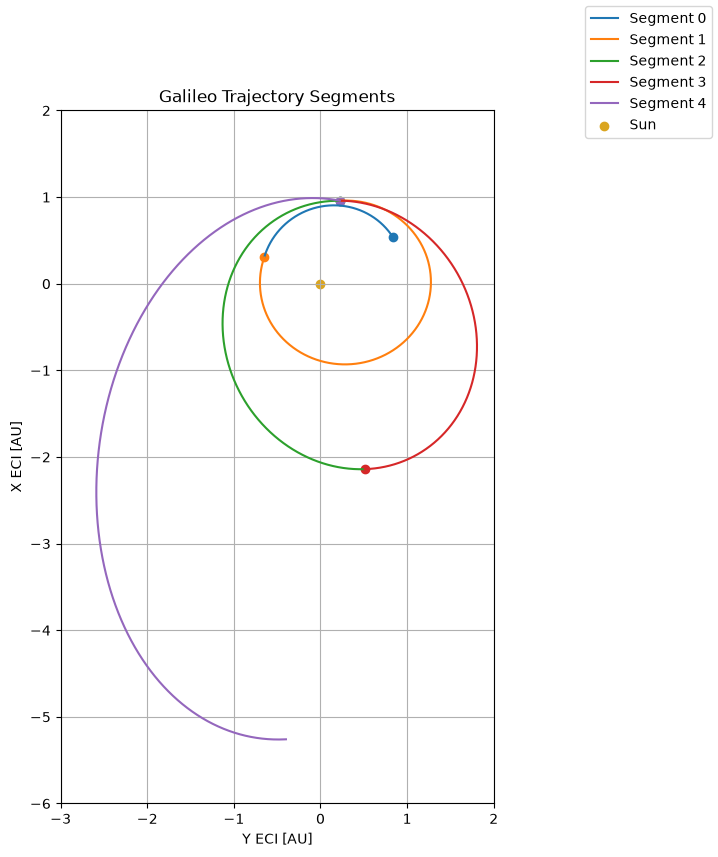

It does look like the trajectories line up!!!


In [125]:
# for flyby,c in zip(relevant_flybys, colors):
#     plot_hyperbolic_characteristics(flyby,c)
    
fig, ax = plt.subplots(figsize=(9, 9))
    
for i,(t,s) in enumerate(zip(t_arrs, planet_r_hci_arr)):
    
    ax.plot(s[:,0] / AU_TO_KM, s[:,1] / AU_TO_KM, label=f"Segment {i}")
    ax.scatter(s[0,0] / AU_TO_KM, s[0,1] / AU_TO_KM)
    
ax.scatter([0],[0], color="goldenrod", label="Sun")
plt.xlabel("Y ECI [AU]")
plt.ylabel("X ECI [AU]")
ax.set_aspect("equal")
ax.set_xlim(-3, 2)
ax.set_ylim(-6, 2)
fig.legend()
ax.grid(True, "both")
plt.title("Galileo Trajectory Segments")
plt.show()

print("It does look like the trajectories line up!!!")

In [110]:
plot_3d(planet_r_hci_arr, t_arrs, bodies={"name": "Sun", "radius": R_SUN}, title="Test of Mercury-Earth")

### Part d

## Problem 3

### Part a

In [112]:
from orbital import ECI_from_HCI

full_t = np.concatenate(t_arrs)
full_traj = np.concatenate(planet_r_hci_arr)

# Earth position
earth_rv0 = np.concatenate((flybys[0].r_HCI, flybys[0].v_HCI))

earth_rv_HCI = solve_ivp(sun_two_body, (full_t[0], full_t[-1]), earth_rv0, method='LSODA', t_eval=full_t, rtol=1e-6, atol=1e-9).y
r_galileo_earth_HCI = full_traj - earth_rv_HCI[:3].T

In [113]:
def spreading_loss(R):
    """dB/m2"""
    if R < 1:
        return np.nan
    return -70.99 - 20*np.log10(R)

losses = [spreading_loss(norm(r)) for r in r_galileo_earth_HCI]

### Part b

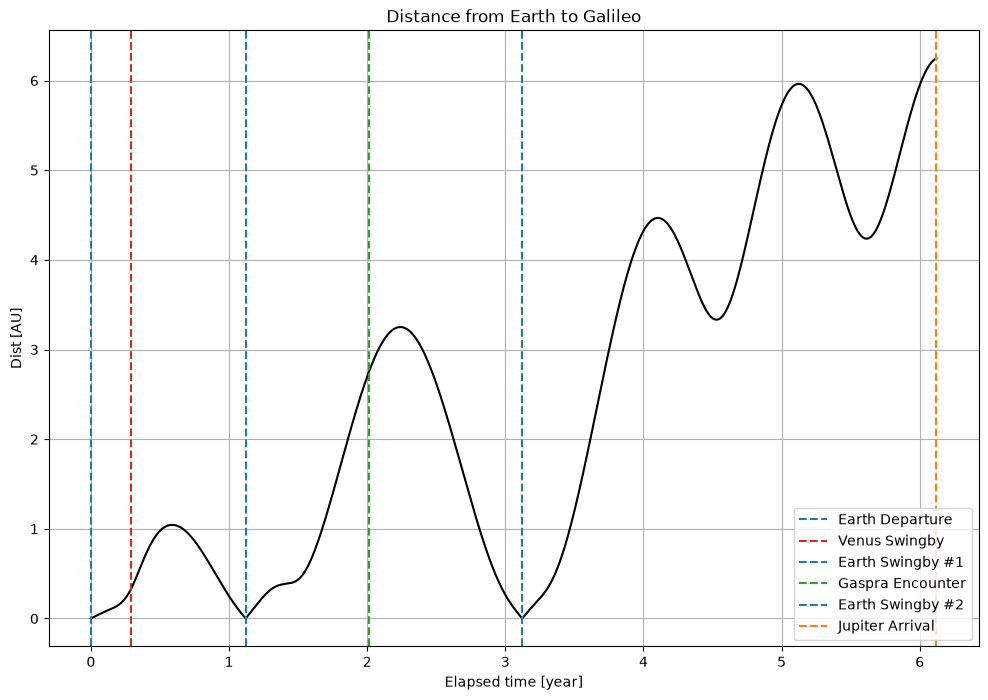

In [ ]:
plt.figure(figsize=(12,8))
plt.title("Distance from Earth to Galileo")

# Plotted thing
plt.plot((full_t - full_t[0]) / DAY_TO_SEC / YEAR_TO_DAY, norm(r_galileo_earth_HCI,axis=1) / AU_TO_KM, color="k")

# Each flyby
for flyby in flybys:
    if "Earth" in flyby.name:
        color = "tab:blue"
    elif "Venus" in flyby.name:
        color = "tab:red"
    elif "Gaspra" in flyby.name:
        color = "tab:green"
    else:
        color = "tab:orange"

    plt.axvline((flyby.jd - full_t[0] / DAY_TO_SEC) / YEAR_TO_DAY, linestyle="--", color=color, label=flyby.name)


plt.xlabel("Elapsed time [yr]")
plt.ylabel("Dist [AU]")
plt.grid(True)
plt.legend()
plt.show()

### Part c

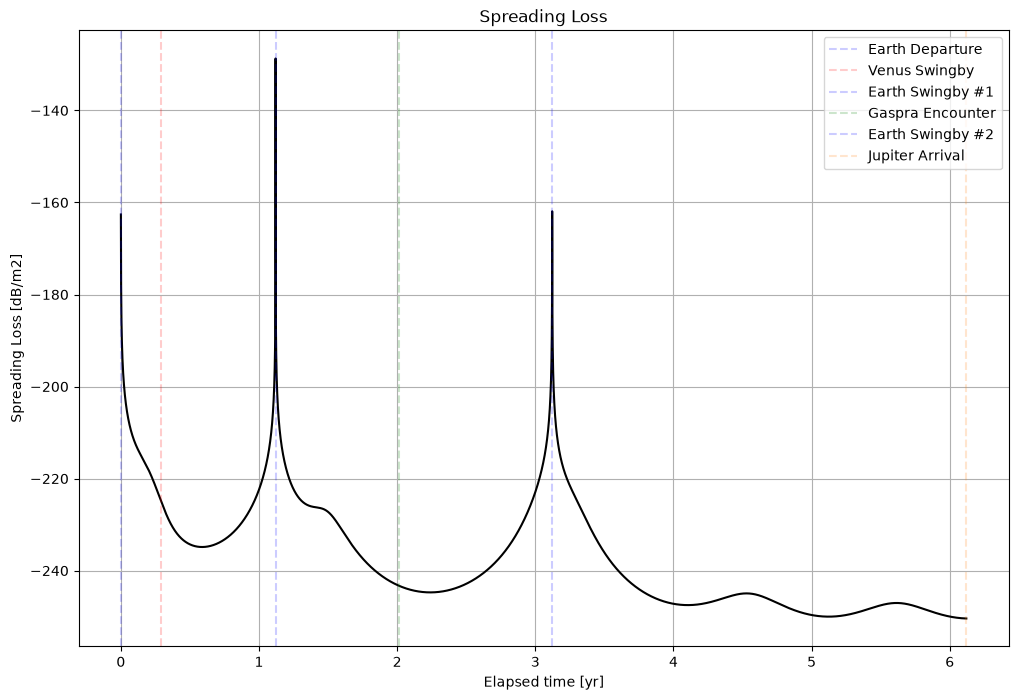

In [137]:
plt.figure(figsize=(12,8))
plt.title("Spreading Loss")

# Plotted thing
plt.plot((full_t - full_t[0]) / DAY_TO_SEC / YEAR_TO_DAY, losses, color="k")

# Each flyby
for flyby in flybys:
    if "Earth" in flyby.name:
        color = "blue"
    elif "Venus" in flyby.name:
        color = "red"
    elif "Gaspra" in flyby.name:
        color = "green"
    else:
        color = "tab:orange"

    plt.axvline((flyby.jd - full_t[0] / DAY_TO_SEC) / YEAR_TO_DAY, linestyle="--", color=color, label=flyby.name, alpha = 0.2)


plt.xlabel("Elapsed time [yr]")
plt.ylabel("Spreading Loss [dB/m2]")
plt.grid(True)
plt.legend()
plt.show()

## Problem 4

Mine:
```bash
===== Flyby Characteristics =====

For Venus Swingby:
	Turning angle: 31.78º
	Hyperbolic Passage Eccentricity: 3.65
	Periapse: 22772.88 km
	Closest approach: 16721.08 km

For Earth Swingby #1:
	Turning angle: 47.76º
	Hyperbolic Passage Eccentricity: 2.47
	Periapse: 7408.24 km
	Closest approach: 1037.23 km

For Earth Swingby #2:
	Turning angle: 52.02º
	Hyperbolic Passage Eccentricity: 2.28
	Periapse: 6434.42 km
	Closest approach: 63.41 km
```

NASA's
```bash
===== Reference Flyby Characteristics =====

For Venus Swingby:
    Hyperbolic Passage Eccentricity: 3.59
    Closest approach: 16000 km

For Earth Swingby #1:
    Hyperbolic Passage Eccentricity: 2.47
    Closest approach: 960 km

For Earth Swingby #2:
    Hyperbolic Passage Eccentricity: 2.32
    Closest approach: 303 km
```

#### Eccentricity
They are all very similar, with my Earth Swingby 1 being exact, and Venus and Earth 2 being about 1.6% and 1.7% different than NASA's. <br>
f


% Eccentricities
% All three are within about 2% of NASA's. earth 1 matches exactly, venus
% is a little high (3.652 vs 3.59) and earth 2 is a little low (2.280 vs
% 2.32). e only depends on the turning angle, which is set by the
% directions of the in and out velocities from lambert, and those are
% pretty robust to small position/timing errors
% Closest approach distances
% Venus and earth 1 are close to NASA's altitudes, but earth 2 is farther
% off (63 vs 303 km). this is because rp depends on (e - 1), so small
% errors in e get amplified a lot. At earth every 0.01 of e is about 50 km
% of altitude, so the 0.04 difference in e at earth 2 accounts for 200 km
% of the gap alone. 63 km is inside the atmosphere, so it
% can't be what galileo actually flew
% These differences can come from a few places. For example, the problem
% says the waypoint times are simplified, so each lambert leg is solved
% for a slightly wrong time. also, patched conics make simplifications about
% the transitions betwene segments and ignore other gravitational influences.
% The real spacecraft also made correction burns between
% flybys, so the actual vinf in and out won't match exactly
% Trajectory plot
% My plot looks the same as NASA's, with planets and trajectories appearing
% in approximately the same places. Their trajectories have smoother
% transitions between the segments however, which can be explained by
% assumed manuever burns and higher fidelity modeling.

# Extra (junk)

In [140]:
test = False
if test:
    # Just visualizing
    from dynamics import two_body


    def sun_two_body(t,x):
        del t
        return two_body(x, MU_SUN)

    
    jd = 2461333.837872444
    labels = [
        "Mercury",
        "Venus",
        "Earth",
        "Mars",
    ]

    planet_rv = []
    for planet_num in range(4):
        test_r, test_v = rv_HCI(planet_num+1,jd, eng) # 2026-10-20 08:06:32.179
        test_t = np.arange(0, 10*DAY_TO_SEC, HOUR_TO_SEC)
        planet_rv.append(
            solve_ivp(sun_two_body, (test_t[0], test_t[-1]), np.concatenate((test_r, test_v)), method='LSODA', t_eval=test_t, rtol=1e-6, atol=1e-9).y
        )
        
    planet_r = [r.T[:,:3] for r in planet_rv]
    plot_3d(planet_r, test_t, bodies={"name": "Sun", "radius": R_SUN}, labels=labels, title="Test of Mercury-Earth")